# Lezione 3 — Riflessione, rifrazione e interferometria termica

Modulo *Radiazione termica e segnatura IR* (Master OQI, prof. R. Li Voti).

Un'onda termica, all'interfaccia fra due mezzi, si riflette e si rifrange.
La legge che lega gli angoli non è quella ottica: dipende dalle diffusività.
In un rivestimento di spessore finito le riflessioni multiple producono
un'interferenza, e da ampiezza e fase contro la frequenza si legge lo
spessore. Se il mezzo si muove, l'onda è trascinata: è l'effetto Doppler termico.

Notebook precedente: `02_lezione_onde_termiche.ipynb`.


## Le relazioni usate sotto

Effusività \(e=\sqrt{k\rho c}\) e numero d'onda \(\sigma=(1+j)/\mu\).

Coefficiente di riflessione in ampiezza di temperatura, incidenza normale:

\[
\Gamma = \frac{e_1-e_2}{e_1+e_2}.
\]

Legge di Snell termica, dalla continuità della fase lungo l'interfaccia
(\(\sigma\propto 1/\sqrt{D}\)):

\[
\frac{\sin\theta_1}{\sqrt{D_1}} = \frac{\sin\theta_2}{\sqrt{D_2}}.
\]

Rivestimento di spessore \(L\) (mezzo 1) su un substrato semi-infinito
(mezzo 2), flusso assorbito in superficie:

\[
\tilde T(0) = \frac{I_0}{k_1\sigma_1}
\frac{1+\Gamma e^{-2\sigma_1 L}}{1-\Gamma e^{-2\sigma_1 L}}.
\]

Mezzo in moto a velocità \(V\) lungo \(z\). L'equazione
\(\partial_t T + V\partial_z T = D\partial_z^2 T\) dà

\[
D\sigma^2 + V\sigma - j\omega = 0.
\]


## 0. Setup


In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8.4, 4.7),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.35,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
    "axes.unicode_minus": False,
})
np.set_printoptions(precision=4, suppress=True)
print("Ambiente pronto.")


Ambiente pronto.


## 1. Legge di Snell termica

Se il secondo mezzo diffonde meglio del primo (\(D_2>D_1\)), il raggio
rifratto si allontana dalla normale e oltre un angolo limite non c'è più
un angolo reale. È il contrario di quello che farebbe un mezzo ottico «più
lento»: qui il parametro che conta è \(\sqrt{D}\), non l'indice.


D2/D1 = 4: angolo limite = 30.0°


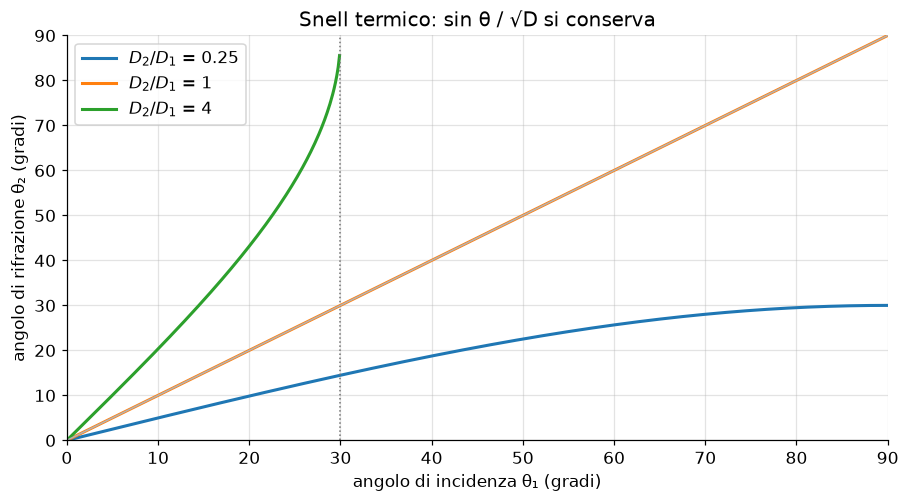

In [2]:
def theta2(theta1, D1, D2):
    """Angolo rifratto. NaN quando sin θ2 > 1 (angolo limite superato)."""
    s = np.sin(theta1) * np.sqrt(D2 / D1)
    out = np.full_like(s, np.nan, dtype=float)
    ok = s <= 1
    out[ok] = np.arcsin(s[ok])
    return out

theta1 = np.linspace(0.0, np.pi / 2, 600)
rapporti = [0.25, 1.0, 4.0]

fig, ax = plt.subplots()
for r in rapporti:
    th2 = theta2(theta1, 1.0, r)
    ax.plot(np.degrees(theta1), np.degrees(th2), lw=2, label=fr"$D_2/D_1$ = {r:g}")
    if r > 1:
        th_c = np.degrees(np.arcsin(np.sqrt(1.0 / r)))
        ax.axvline(th_c, color="0.45", ls=":", lw=1)
        print(f"D2/D1 = {r:g}: angolo limite = {th_c:.1f}°")
ax.plot([0, 90], [0, 90], color="0.7", lw=1)
ax.set_xlabel("angolo di incidenza θ₁ (gradi)")
ax.set_ylabel("angolo di rifrazione θ₂ (gradi)")
ax.set_title("Snell termico: sin θ / √D si conserva")
ax.set_xlim(0, 90)
ax.set_ylim(0, 90)
ax.legend()
fig.tight_layout()
plt.show()

# D2/D1 = 4 → sin θc = 1/2 → 30°.
assert np.isclose(np.degrees(np.arcsin(np.sqrt(1 / 4))), 30.0)


## 2. Specchio termico

\(\Gamma\) dipende solo dal contrasto di effusività. Uno specchio termico è
un'interfaccia con \(|\Gamma|\) vicino a 1:

- substrato molto effusivo (\(e_2\gg e_1\)): \(\Gamma\to -1\), la temperatura
  riflessa cambia segno;
- substrato isolante (\(e_2\ll e_1\)): \(\Gamma\to +1\), l'eco torna in fase.

È la stessa \(R\) del lampo della lezione 1, riletta in regime periodico.


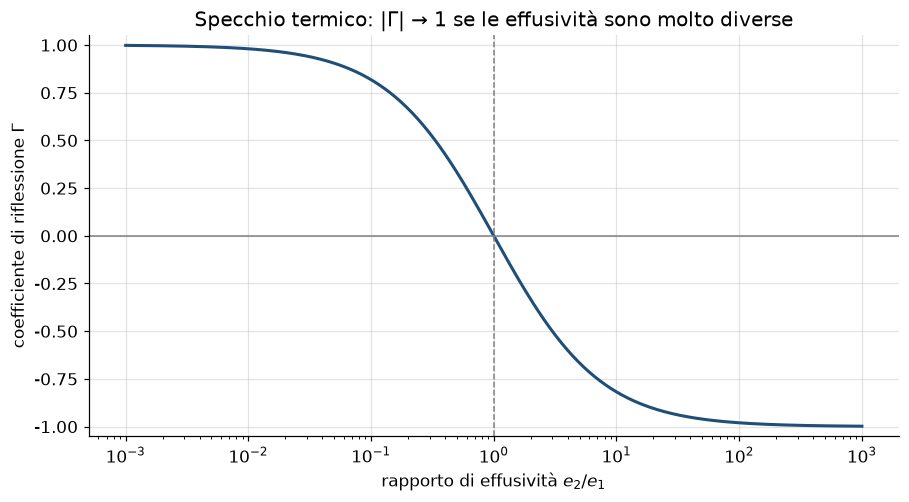

interfaccia                   Γ
vernice su acciaio       -0.310
metallo su polimero      +0.918
bronzo su aria           +0.999


In [3]:
rapporto = np.geomspace(1e-3, 1e3, 400)   # e2 / e1
Gamma = (1 - rapporto) / (1 + rapporto)

fig, ax = plt.subplots()
ax.semilogx(rapporto, Gamma, color="#1f4e79", lw=2)
ax.axhline(0.0, color="0.5", lw=1)
ax.axvline(1.0, color="0.5", ls="--", lw=1)
ax.set_xlabel(r"rapporto di effusività $e_2/e_1$")
ax.set_ylabel(r"coefficiente di riflessione $\Gamma$")
ax.set_title("Specchio termico: |Γ| → 1 se le effusività sono molto diverse")
ax.set_ylim(-1.05, 1.05)
fig.tight_layout()
plt.show()

assert (1 - 1.0) / (1 + 1.0) == 0.0
i_zero = np.argmin(np.abs(rapporto - 1.0))
assert abs(Gamma[i_zero]) < 0.03
assert Gamma[0] > 0.99 and Gamma[-1] < -0.99

# Qualche coppia, con effusività tipiche (J m⁻² K⁻¹ s⁻½).
coppie = {
    "vernice su acciaio": (4.0e3, 7.6e3),
    "metallo su polimero": (1.4e4, 6.0e2),
    "bronzo su aria": (1.3e4, 5.5),
}
print(f"{'interfaccia':22} {'Γ':>8}")
for nome, (e1, e2) in coppie.items():
    print(f"{nome:22} {(e1-e2)/(e1+e2):+8.3f}")


## 3. Interferenza in un rivestimento

Alle basse frequenze \(\mu\gg L\): l'onda attraversa il rivestimento e la
superficie risponde con l'effusività del **substrato**. Alle alte frequenze
\(\mu\ll L\): il substrato non si vede e risponde il **rivestimento**.
In mezzo, le riflessioni multiple modulano ampiezza e fase. Il primo giro
di fase sta vicino alla frequenza per cui \(\mu(f)\approx L\),

\[
f_L = \frac{D_1}{\pi L^2}.
\]


Γ = -0.313
μ = L quando f = 12.43 Hz


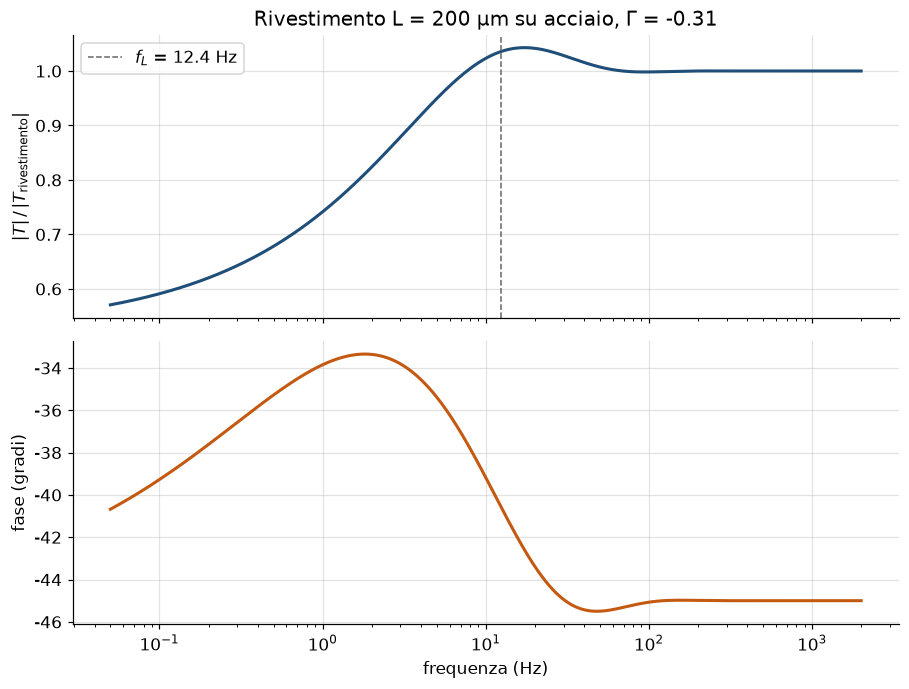

Controlli agli estremi: bassa frequenza = substrato, alta frequenza = rivestimento.


In [4]:
def temperatura_rivestimento(f, L, k1, D1, e1, e2, I0=1.0):
    """Temperatura complessa in superficie di un rivestimento su substrato."""
    omega = 2 * np.pi * f
    sigma = np.sqrt(1j * omega / D1)
    Gamma = (e1 - e2) / (e1 + e2)
    eco = np.exp(-2 * sigma * L)
    return (I0 / (k1 * sigma)) * (1 + Gamma * eco) / (1 - Gamma * eco)

# Rivestimento a bassa effusività su acciaio: è il caso «coating su bulk» della lezione.
k1, rho1, c1 = 5.0, 4000.0, 800.0
D1 = k1 / (rho1 * c1)
e1 = np.sqrt(k1 * rho1 * c1)
k2, rho2, c2 = 15.0, 7800.0, 500.0
e2 = np.sqrt(k2 * rho2 * c2)
L = 200e-6
Gamma = (e1 - e2) / (e1 + e2)
fL = D1 / (np.pi * L**2)
print(f"Γ = {Gamma:+.3f}")
print(f"μ = L quando f = {fL:.2f} Hz")

f = np.geomspace(0.05, 2e3, 600)
T = temperatura_rivestimento(f, L, k1, D1, e1, e2)
# Riferimento: semi-infinito del solo rivestimento, che va come 1/√f.
T_coat = 1.0 / (e1 * np.sqrt(1j * 2 * np.pi * f))
T_sub = 1.0 / (e2 * np.sqrt(1j * 2 * np.pi * f))
rapporto = T / T_coat

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(8.4, 6.4))
ax1.semilogx(f, np.abs(rapporto), color="#1f4e79", lw=2)
ax1.axvline(fL, color="0.4", ls="--", lw=1, label=fr"$f_L$ = {fL:.1f} Hz")
ax1.set_ylabel(r"$|T|\,/\,|T_\mathrm{rivestimento}|$")
ax1.set_title(f"Rivestimento L = {L*1e6:.0f} μm su acciaio, Γ = {Gamma:+.2f}")
ax1.legend()
ax2.semilogx(f, np.degrees(np.angle(T)), color="#c45911", lw=2)
ax2.set_xlabel("frequenza (Hz)")
ax2.set_ylabel("fase (gradi)")
fig.tight_layout()
plt.show()

# Bassa frequenza → si vede il substrato. Alta frequenza → si vede il rivestimento.
bassa = temperatura_rivestimento(np.array([1e-8]), L, k1, D1, e1, e2)[0]
alta = temperatura_rivestimento(np.array([1e6]), L, k1, D1, e1, e2)[0]
sub = 1.0 / (e2 * np.sqrt(1j * 2 * np.pi * 1e-8))
coat = 1.0 / (e1 * np.sqrt(1j * 2 * np.pi * 1e6))
assert np.isclose(bassa, sub, rtol=1e-3)
assert np.isclose(alta, coat, rtol=1e-3)
print("Controlli agli estremi: bassa frequenza = substrato, alta frequenza = rivestimento.")


## 4. Effetto Doppler termico

Nel suono il Doppler sposta la frequenza. In un'onda termica il mezzo che
scorre cambia **decadimento e fase**, in modo diverso a valle e a monte
della sorgente. Con il parametro

\[
\gamma = \frac{V}{\sqrt{2\omega D}}
\]

(\(\gamma=0\) è il mezzo fermo; i valori disegnati a lezione sono dell'ordine
di \(0{,}5\)) la radice con parte reale positiva è

\[
\sigma = \frac{-V + \sqrt{V^2 + 4 j \omega D}}{2D}.
\]

A valle (\(\gamma>0\)) l'ampiezza si spegne più lentamente: il flusso trasporta
il calore. A monte si schiaccia contro la sorgente.


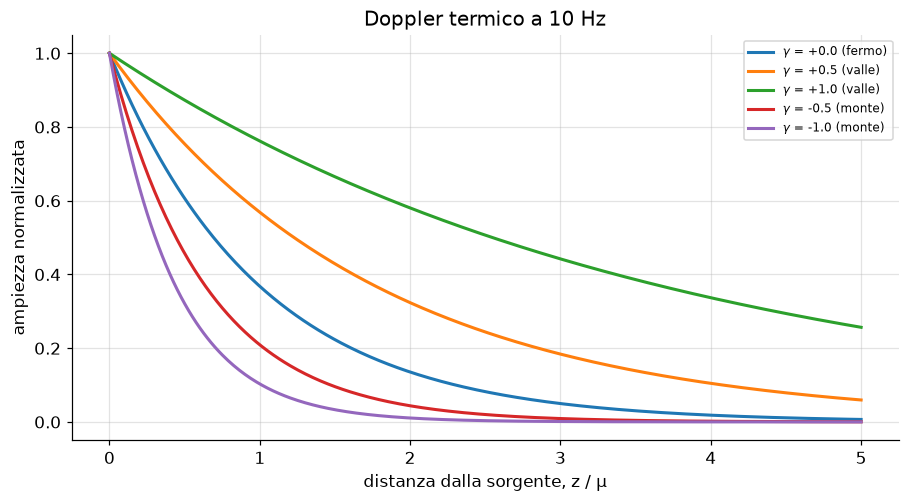

Re(σ)·μ : fermo 1.00, valle 0.27, monte 2.27


In [5]:
def sigma_doppler(omega, D, V):
    return (-V + np.sqrt(V**2 + 4j * omega * D)) / (2 * D)

D = 4e-6          # m²/s, ordine di un metallo
f0 = 10.0
omega = 2 * np.pi * f0
mu = np.sqrt(2 * D / omega)
z = np.linspace(0.0, 5 * mu, 400)

fig, ax = plt.subplots()
for gamma in (0.0, 0.5, 1.0, -0.5, -1.0):
    V = gamma * np.sqrt(2 * omega * D)
    sig = sigma_doppler(omega, D, V)
    amp = np.exp(-sig.real * z)
    verso = "valle" if gamma > 0 else ("monte" if gamma < 0 else "fermo")
    ax.plot(z / mu, amp, lw=2, label=fr"$\gamma$ = {gamma:+.1f} ({verso})")
ax.set_xlabel("distanza dalla sorgente, z / μ")
ax.set_ylabel("ampiezza normalizzata")
ax.set_title(f"Doppler termico a {f0:.0f} Hz")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

# Mezzo fermo: Re(σ) = 1/μ.
sig0 = sigma_doppler(omega, D, 0.0)
assert np.isclose(sig0.real, 1 / mu, rtol=1e-8)
# A valle il decadimento è più lento che a monte.
sig_piu = sigma_doppler(omega, D, +np.sqrt(2 * omega * D))
sig_meno = sigma_doppler(omega, D, -np.sqrt(2 * omega * D))
assert sig_piu.real < sig0.real < sig_meno.real
print(f"Re(σ)·μ : fermo {sig0.real*mu:.2f}, valle {sig_piu.real*mu:.2f}, monte {sig_meno.real*mu:.2f}")


## In sintesi

- La Snell termica conserva \(\sin\theta/\sqrt{D}\). Se \(D_2>D_1\) esiste un angolo limite.
- \(\Gamma=(e_1-e_2)/(e_1+e_2)\). Lo specchio termico è un contrasto forte di effusività, con o senza inversione di fase.
- Un rivestimento, al variare di \(f\), passa dal substrato (bassa frequenza) al film (alta frequenza). La frequenza di transito è \(D/(\pi L^2)\).
- Il moto del mezzo non sposta \(\omega\): allunga l'onda a valle e la comprime a monte. A \(\gamma=0\) si recupera \(\sigma=(1+j)/\mu\).
